# The zone of model adequacy

*How close to the ideal could a model of these data be expected to come? A split-half analysis of the human data, after Dome and Wills (2025, Zone of Model Adequacy section).*

g-distance places a model on the plane of accommodation ($\alpha$) and excess flexibility ($\beta$), and measures its distance from the PAS point, the ideal model (see [gdistance.ipynb](gdistance.ipynb)). With perfect information about human behaviour, the ideal model would sit at that point. But information is never perfect. The sample of people is finite, so some patterns people could show are not observed, and discretizing human behaviour with a statistical threshold makes errors of both commission and omission: detecting a pattern that is not there, and missing one that is. Under these conditions, even a perfect model could not be expected to sit at the PAS point. How close could one expect it to be?

Dome and Wills (2025) estimate a lower bound with a **split-half analysis** of the human data, after the "noise ceiling" used to evaluate models against neuroscience data (Kaniuth & Hebart, 2022; Nili et al., 2014). With a sufficiently large sample, the best predictor of the behaviour of a randomly chosen half of the participants is the other half. With a smaller sample, half the participants may not capture the full heterogeneity of people, so the two halves do not match perfectly: there is noise in the data. Even so, a model that predicts people worse than other people do could be improved.

The analysis splits the participants into two random halves, calculates the g-distance of one half (arbitrarily treated as the model) from the other (arbitrarily treated as the data), and repeats this many times with different random splits. The range these noise-ceiling estimates cover on each axis is the **zone of model adequacy**: a benchmark for model development specific to the data set.

In [1]:
import sys

import math
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

from psp import clobe

sys.path.insert(0, "..")  # for notebooks/figure_style.py
from figure_style import aqua, blue, figures, ink, light, muted, orange, reference, titled

show = figures("clobe-zone-of-adequacy")

colours = {"linear": blue, "quadratic": orange, "random": aqua}
markers = {"linear": "o", "quadratic": "^", "random": "s"}  # a second cue besides colour,
styles = {"linear": "-", "quadratic": "--", "random": "-."}  # for print and colour-blind readers


## The data and the models

The experiment of [getting-started.ipynb](getting-started.ipynb), with more people: 200 participants respond to four stimuli whose feature $x$ is $-1.5, -0.5, 0.5, 1.5$. Each has their own slope around 0.5 plus a little noise for each stimulus, and each response rate is a proportion of 20 trials. Their patterns are built with a threshold of 0.1, and the universal set is the 183 semiorders of four stimuli.

The three models are those of [gdistance.ipynb](gdistance.ipynb): the **linear** model $p_i = \sigma(b \, x_i)$, which can only produce monotonic patterns; the **quadratic** model $p_i = \sigma(b \, x_i + c \, x_i^2)$, which can also produce U-shapes and inverted U-shapes; and the **random** model, 2,000 sets of independent uniform probabilities, which can produce almost anything.

In [2]:
thresholds, w = (0.1, -0.1), 0.5
universal = clobe.semiorders(4)
x = torch.tensor([-1.5, -0.5, 0.5, 1.5], dtype=torch.float64)


def participants(n, generator):
    slopes = 0.5 + torch.randn(n, generator=generator, dtype=torch.float64)
    p = torch.sigmoid(slopes[:, None] * x + 0.3 * torch.randn(n, 4, generator=generator,
                                                              dtype=torch.float64))
    return torch.binomial(torch.full_like(p, 20.0), p, generator=generator) / 20


g = torch.Generator().manual_seed(2025)
results = participants(200, g)
human = clobe.patterns(results, thresholds)

grid = torch.arange(-30, 31, dtype=torch.float64) / 10
b, c = (t.reshape(-1, 1) for t in torch.meshgrid(grid, grid, indexing="ij"))
models = {
    "linear": torch.sigmoid(grid[:, None] * x),
    "quadratic": torch.sigmoid(b * x + c * x**2),
    "random": torch.rand(2000, 4, generator=g, dtype=torch.float64),
}
scores = pd.DataFrame({
    name: vars(clobe.gdistance(human.inequality_matrices,
                               clobe.patterns(out, thresholds).inequality_matrices,
                               universal, w, human.frequencies))
    for name, out in models.items()
}).T[["alpha", "beta", "gdistance"]].astype(float)
display(Markdown(f"The 200 participants show {human.n} of the {universal} possible patterns."))
scores.round(3)

The 200 participants show 62 of the 183 possible patterns.

,alpha,beta,gdistance
linear,0.195,0.025,0.569
quadratic,0.665,0.322,0.329
random,0.965,0.727,0.515


## One split

Shuffle the participants, call the first half the data and the second half the model, and compare them as one would compare a model with data: the patterns of each half, the frequencies of the data's patterns, and `gdistance()`.

In [3]:
def one_split(results, order):
    half = len(order) // 2
    data = clobe.patterns(results[order[:half]], thresholds)
    model = clobe.patterns(results[order[half:]], thresholds)
    return clobe.gdistance(data.inequality_matrices, model.inequality_matrices,
                           universal, w, data.frequencies)


one_split(results, torch.randperm(200, generator=torch.Generator().manual_seed(1)))

GDistanceResult(gdistance=0.2136800965777332, alpha=0.73, beta=0.1357142857142857, accommodation=tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  9, 10, 11, 12, 14, 18, 19, 21, 22, 25,
        26, 30, 32, 40]))

## Many splits at once

The paper repeats this 10,000 times. A loop of `gdistance()` calls would do, but every split only regroups the same participants, so all the splits can be computed at once. Each participant's pattern is found once; a split is then a choice of which participants are in the data half, and the patterns of each half follow from a matrix product with a table of which participant shows which pattern. The first 100 splits are checked against `gdistance()`.

In [4]:
def split_half(results, splits=10_000, seed=0):
    # alpha, beta and g of one half against the other, for many random splits
    n, half = results.shape[0], results.shape[0] // 2
    everyone = clobe.patterns(results, thresholds)
    shows = torch.nn.functional.one_hot(everyone.pattern, everyone.n).double()  # participant x pattern
    generator = torch.Generator().manual_seed(seed)
    orders = torch.stack([torch.randperm(n, generator=generator) for _ in range(splits)])
    in_data = torch.zeros(splits, n, dtype=torch.bool).scatter_(1, orders[:, :half], True)
    data_counts = in_data.double() @ shows  # how many people in the data half show each pattern
    in_model = ((~in_data).double() @ shows) > 0  # the patterns the model half produces
    in_data_patterns = data_counts > 0
    alpha = (data_counts / half * in_model).sum(1)
    beta = (in_model & ~in_data_patterns).sum(1) / (universal - in_data_patterns.sum(1))
    g = torch.sqrt(w * (1 - alpha) ** 2 + (1 - w) * beta**2)
    return pd.DataFrame({"alpha": alpha, "beta": beta, "gdistance": g}), orders


halves, orders = split_half(results)
for s in range(100):
    direct = one_split(results, orders[s])
    assert np.allclose([direct.alpha, direct.beta, direct.gdistance], halves.iloc[s], rtol=1e-12)
halves.describe(percentiles=[0.025, 0.5, 0.975]).loc[["mean", "min", "2.5%", "50%", "97.5%", "max"]].round(3)

,alpha,beta,gdistance
mean,0.755,0.141,0.201
min,0.510,0.069,0.139
2.5%,0.670,0.110,0.159
50%,0.760,0.142,0.199
97.5%,0.840,0.171,0.254
max,0.900,0.199,0.356


## The zone on the α-β plane

Each grey dot is one split; the labelled point is their mean. The zone of model adequacy is the range the dots cover on each axis, drawn as a dashed box on the right, where the plane is enlarged around it.

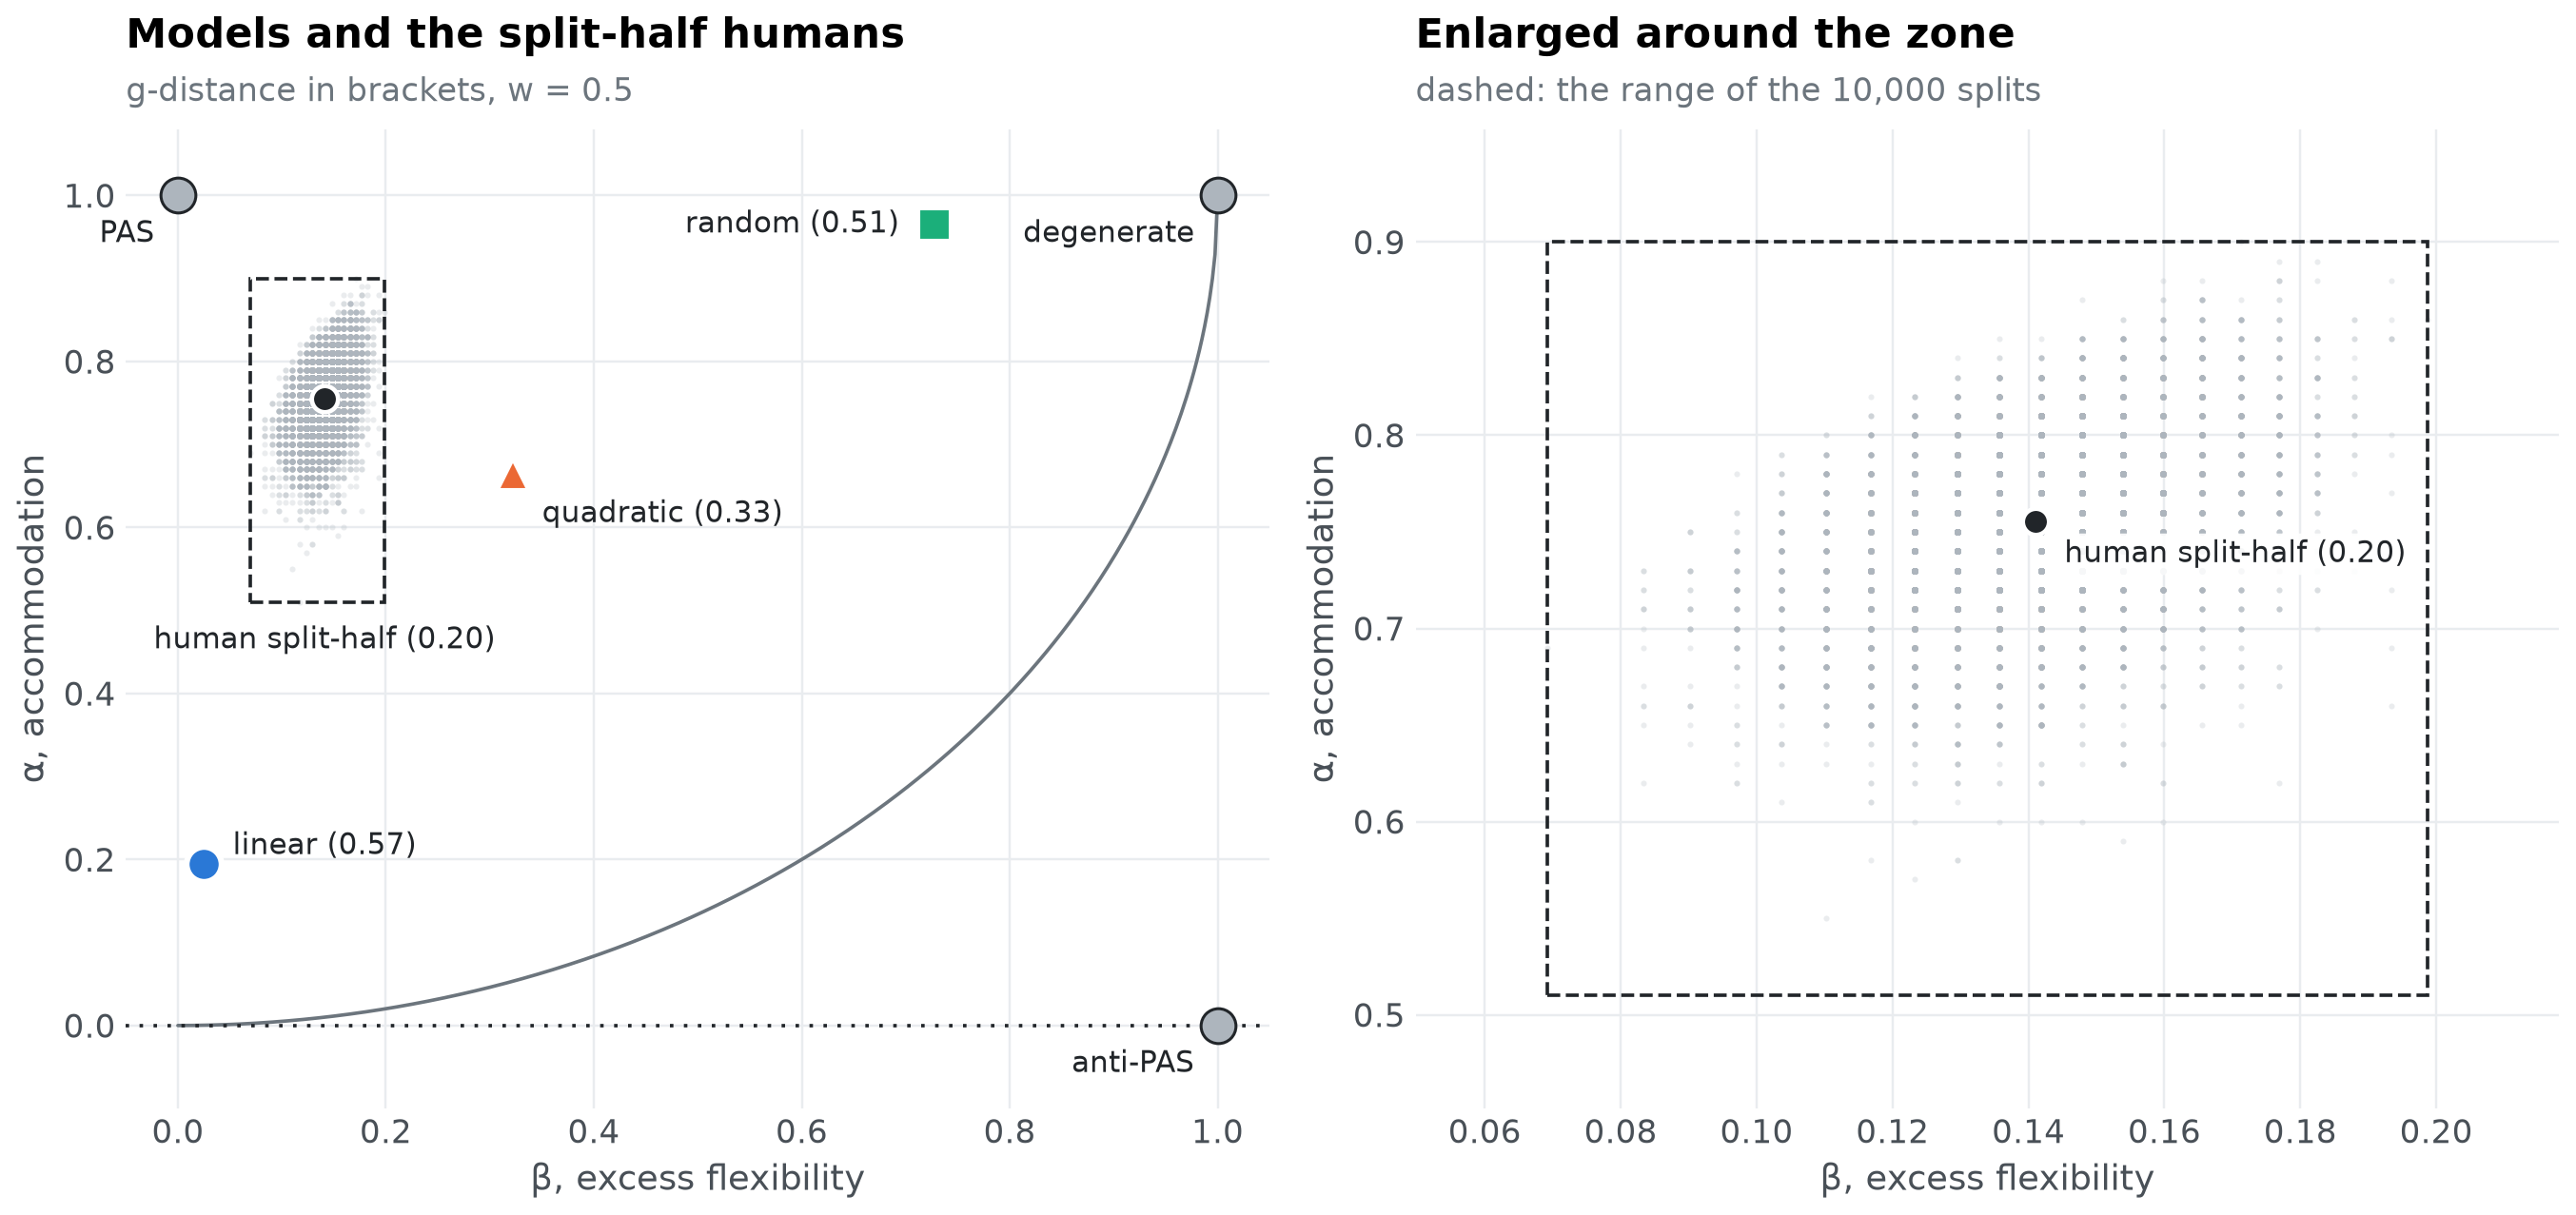

In [5]:
zone = halves.agg(["min", "max"])
mean = halves.mean()


def plane(ax, zoom):
    beta_line = np.linspace(0, 1, 400)
    ax.plot(beta_line, 1 - np.sqrt((1 - w) * (1 - beta_line**2) / w), color=muted, linewidth=1.2)
    ax.axhline(0, color=ink, linestyle=(0, (1, 3)), linewidth=1.2)
    ax.scatter(halves.beta, halves.alpha, s=4, color=reference, alpha=0.25, linewidths=0,
               rasterized=True)
    ax.add_patch(plt.Rectangle((zone.beta["min"], zone.alpha["min"]),
                               zone.beta["max"] - zone.beta["min"], zone.alpha["max"] - zone.alpha["min"],
                               fill=False, edgecolor=ink, linestyle="--", linewidth=1.2))
    ax.plot(mean.beta, mean.alpha, "o", color=ink, markersize=9, markeredgecolor="white",
            markeredgewidth=1.5)
    if zoom:
        ax.annotate(f"human split-half ({mean.gdistance:.2f})", (mean.beta, mean.alpha),
                    xytext=(10, -14), textcoords="offset points", color=ink, fontsize=10,
                    bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none",
                          "alpha": 0.9})
    else:
        ax.annotate(f"human split-half ({mean.gdistance:.2f})", (mean.beta, zone.alpha["min"]),
                    xytext=(0, -8), textcoords="offset points", ha="center", va="top", color=ink,
                    fontsize=10)
    for name, row in scores.iterrows():
        ax.plot(row.beta, row.alpha, markers[name], color=colours[name], markersize=12,
                markeredgecolor="white", markeredgewidth=2)
        offset, align = {"random": ((-12, 0), "right"), "quadratic": ((10, -14), "left")}.get(
            name, ((10, 6), "left"))
        ax.annotate(f"{name} ({row.gdistance:.2f})", (row.beta, row.alpha), xytext=offset,
                    textcoords="offset points", ha=align, va="center", color=ink, fontsize=10,
                    annotation_clip=True)
    if not zoom:
        for b_, a_, name in [(0, 1, "PAS"), (1, 1, "degenerate"), (1, 0, "anti-PAS")]:
            ax.plot(b_, a_, "o", color=reference, markersize=12, markeredgecolor=ink)
            ax.annotate(name, (b_, a_), xytext=(-8, -16), textcoords="offset points", ha="right",
                        color=ink, fontsize=10)
        ax.set(xlim=(-0.05, 1.05), ylim=(-0.1, 1.08))
    else:
        pad_b = (zone.beta["max"] - zone.beta["min"]) * 0.15
        pad_a = (zone.alpha["max"] - zone.alpha["min"]) * 0.15
        ax.set(xlim=(max(-0.01, zone.beta["min"] - pad_b), zone.beta["max"] + pad_b),
               ylim=(zone.alpha["min"] - pad_a, min(1.01, zone.alpha["max"] + pad_a)))
    ax.set(xlabel="β, excess flexibility", ylabel="α, accommodation")


fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 6))
plane(left, zoom=False)
titled(left, "Models and the split-half humans", "g-distance in brackets, w = 0.5")
plane(right, zoom=True)
titled(right, "Enlarged around the zone", "dashed: the range of the 10,000 splits")
fig.tight_layout()
show(fig, "zone-plane")

## Where each model falls

On each axis separately, a model can be **in the zone** (within the range of the splits), **beyond it** (better than every split: higher $\alpha$, or lower $\beta$), or **outside it** (worse than every split). The share of splits a model beats tells how far into the zone it reaches.

In [6]:
def place(value, samples, higher_is_better):
    beats = float(((samples < value) if higher_is_better else (samples > value)).mean())
    if samples.min() <= value <= samples.max():
        where = "in the zone"
    elif (value > samples.max()) == higher_is_better:
        where = "beyond the zone"
    else:
        where = "outside the zone"
    return beats, where


rows = {}
for name, row in scores.iterrows():
    alpha_beats, alpha_where = place(row.alpha, halves.alpha, True)
    beta_beats, beta_where = place(row.beta, halves.beta, False)
    rows[name] = {"α": f"{row.alpha:.3f}", "α beats": f"{alpha_beats:.0%} of splits",
                  "on α": alpha_where, "β": f"{row.beta:.3f}", "β beats": f"{beta_beats:.0%} of splits",
                  "on β": beta_where, "g": f"{row.gdistance:.3f}"}
pd.DataFrame(rows).T

,α,α beats,on α,β,β beats,on β,g
linear,0.195,0% of splits,outside the zone,0.025,100% of splits,beyond the zone,0.569
quadratic,0.665,2% of splits,in the zone,0.322,0% of splits,outside the zone,0.329
random,0.965,100% of splits,beyond the zone,0.727,0% of splits,outside the zone,0.515


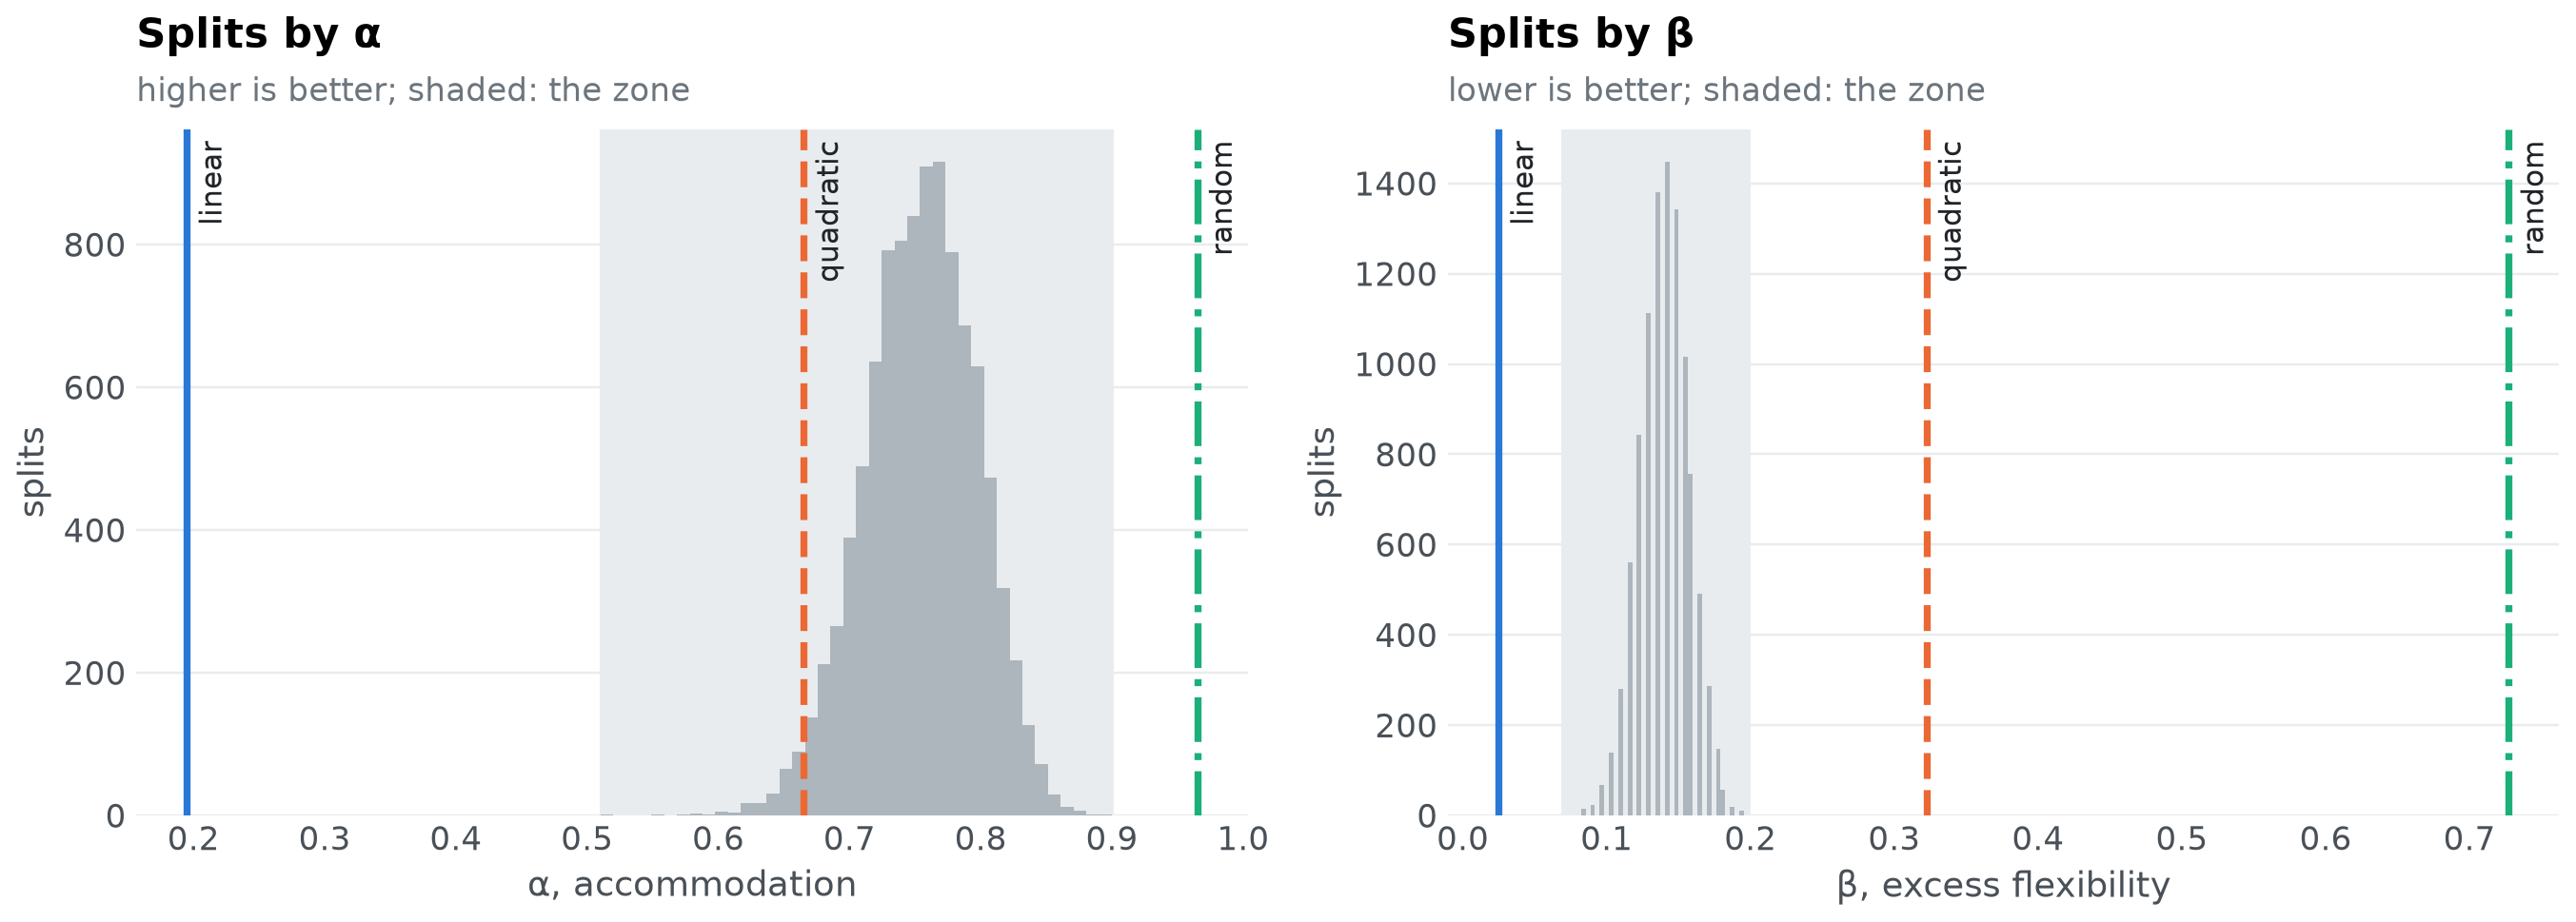

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, column, label, better in [(axes[0], "alpha", "α, accommodation", "higher"),
                                  (axes[1], "beta", "β, excess flexibility", "lower")]:
    ax.hist(halves[column], bins=40, color=reference)
    ax.axvspan(zone[column]["min"], zone[column]["max"], color=light, zorder=0)
    for name, value in scores[column].items():
        ax.axvline(value, color=colours[name], linestyle=styles[name], linewidth=2.4)
        ax.annotate(name, (value, 1), xycoords=("data", "axes fraction"), xytext=(4, -4),
                    textcoords="offset points", color=ink, fontsize=10, va="top", rotation=90)
    ax.set(xlabel=label, ylabel="splits")
    ax.grid(axis="x", visible=False)
    titled(ax, f"Splits by {label.split(',')[0]}", f"{better} is better; shaded: the zone")
fig.tight_layout()
show(fig, "zone-histograms")

In [8]:
def verdict(name):
    _, on_alpha = place(scores.alpha[name], halves.alpha, True)
    _, on_beta = place(scores.beta[name], halves.beta, False)
    return on_alpha, on_beta


lines = [f"- **{name}**: {verdict(name)[0]} on α, {verdict(name)[1]} on β." for name in scores.index]
display(Markdown("\n".join(lines)))

- **linear**: outside the zone on α, beyond the zone on β.
- **quadratic**: in the zone on α, outside the zone on β.
- **random**: beyond the zone on α, outside the zone on β.

A model can be beyond the zone on $\alpha$: it then accommodates more of the people than half of the people do. That is not implausible. Half the sample is not enough to show every pattern the full sample shows, so the split-half humans miss some of the patterns the other half shows, while a model is compared with the full sample. With a large enough sample no model could outperform the data, but with the sample at hand a model can "max out" the accommodation component of the split-half analysis.

Where the zone lies on $\beta$ depends on how many of the possible patterns people show. For the split-half humans, $\beta$ counts the patterns the model half shows that the data half does not, out of all the patterns the data half does not show. Its numerator can never exceed the number of patterns people show, while its denominator is the rest of the universal set.

In [9]:
display(Markdown(
    f"In Dome and Wills (2025), people showed 90 of the over 2,000 patterns that could have been observed, "
    f"so the denominator was large and the zone sat close to zero on β. Here, people show {human.n} of "
    f"{universal}, so the zone on β runs from {zone.beta['min']:.2f} to {zone.beta['max']:.2f}. Either way, "
    "a model that produces many patterns nobody showed is far outside the zone on β, however well it "
    "accommodates."
))

In Dome and Wills (2025), people showed 90 of the over 2,000 patterns that could have been observed, so the denominator was large and the zone sat close to zero on β. Here, people show 62 of 183, so the zone on β runs from 0.07 to 0.20. Either way, a model that produces many patterns nobody showed is far outside the zone on β, however well it accommodates.

## The zone depends on the data set

The zone is specific to the data: it moves with the number of people, the task and how their behaviour is discretized. With more participants, each half captures more of the patterns people show. The halves then accommodate each other better, so $\alpha$ rises; and fewer of the possible patterns are left unobserved by the data half, so each pattern the other half adds weighs more, and $\beta$ rises too.

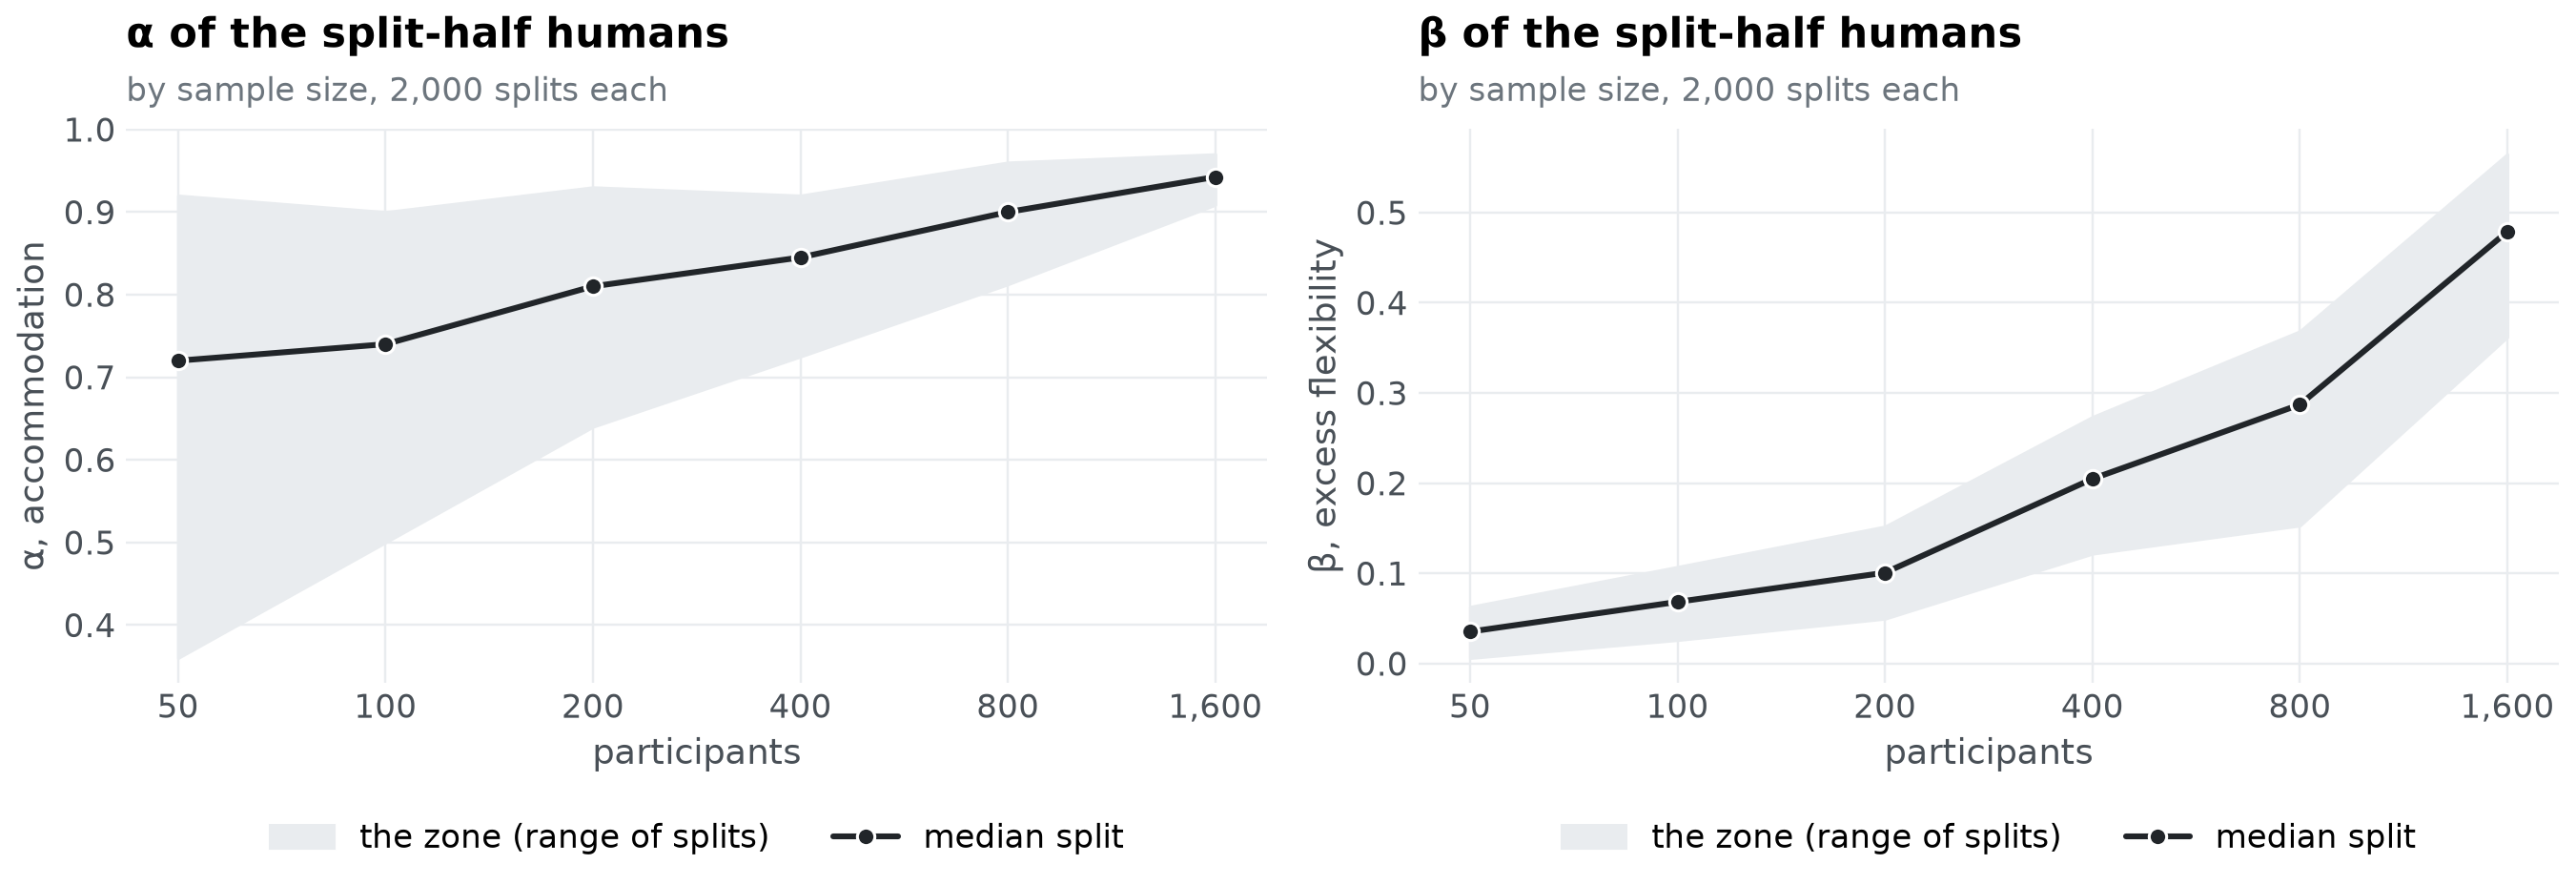

In [10]:
more = participants(1600, torch.Generator().manual_seed(7))
sizes = [50, 100, 200, 400, 800, 1600]
ranges = {n: split_half(more[:n], splits=2_000)[0] for n in sizes}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, column, label in [(axes[0], "alpha", "α, accommodation"), (axes[1], "beta", "β, excess flexibility")]:
    low = [ranges[n][column].min() for n in sizes]
    high = [ranges[n][column].max() for n in sizes]
    middle = [ranges[n][column].median() for n in sizes]
    ax.fill_between(sizes, low, high, color=light, label="the zone (range of splits)")
    ax.plot(sizes, middle, "-o", color=ink, linewidth=2, markersize=6, markeredgecolor="white",
            label="median split")
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set(xticks=sizes, xlabel="participants", ylabel=label)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    titled(ax, f"{label.split(',')[0]} of the split-half humans", "by sample size, 2,000 splits each")
fig.tight_layout()
show(fig, "zone-by-sample-size")

## In practice

1. Collect the results of every participant, and build their patterns with the thresholds the models will be judged by.
2. Run `split_half()` above (or the loop of `one_split()`) for many random splits.
3. Place each model on the plane against the cloud of splits, axis by axis: in the zone, beyond it, or outside it.

A model outside the zone on an axis is worse on that axis than people are at predicting each other, and could be improved. A model in or beyond the zone on both axes is as adequate as these data allow one to tell.

## References

Dome, L., & Wills, A. J. (2025). g-Distance: On the comparison of model and human heterogeneity. *Psychological Review, 132*(3), 632-655. https://doi.org/10.1037/rev0000550

Kaniuth, P., & Hebart, M. N. (2022). Feature-reweighted representational similarity analysis: A method for improving the fit between computational models, brains, and behavior. *NeuroImage, 257*, Article 119294. https://doi.org/10.1016/j.neuroimage.2022.119294

Nili, H., Wingfield, C., Walther, A., Su, L., Marslen-Wilson, W., & Kriegeskorte, N. (2014). A toolbox for representational similarity analysis. *PLOS Computational Biology, 10*(4), Article e1003553. https://doi.org/10.1371/journal.pcbi.1003553